[![Ouvrir dans Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/philippe-amuzuga/Meca-IA_Ed2026/blob/main/meca-ia/C03/E03-1_Surveillance_Vibratoire_CORRIGE.ipynb)

# Surveillance vibratoire d'une machine : résumer les données et repérer l'atypique

## Le contexte

Un parc de pompes est surveillé par des capteurs : vibrations en plusieurs bandes de fréquence, température de palier, courant, pression de graissage, émission acoustique. À chaque relevé, le responsable maintenance voudrait connaître la durée de vie restante de la machine, pour planifier l'arrêt avant la panne et non après.

Avant de modéliser, il faut résumer ce que contient le relevé et repérer ce qui sort de l'ordinaire : cases vides, lignes presque vides, valeurs extrêmes, colonnes qui sont en réalité une conséquence de la cible. Un modèle ne corrige pas un relevé mal lu.

C'est un problème de régression : la grandeur à prédire est un nombre, en heures.

Défi : prédire `duree_vie_restante_RUL_h` et obtenir un R² supérieur à celui du modèle de départ sur la base de test. Ce modèle de départ n'utilise qu'une seule variable, l'âge de la machine, et atteint un R² de 0,883 : à vous d'ajouter les autres. La règle de découpage est fixée plus bas. La base de test sert à mesurer, jamais à apprendre ni à régler.

## Les données

Fichier `MecaIA-Surveillance_Vibratoire.xlsx`, dans le dossier `donnees` du dépôt : 150 relevés, 25 colonnes. Une ligne est un relevé sur une machine.

| Colonne | Signification | Unité |
|---|---|---|
| `ZONE_ATELIER`, `TYPE_MACHINE`, `ALIMENTATION`, `MODE_FONCTIONNEMENT`, `ETAT_LIGNE`, `TYPE_LUBRIFIANT` | zone, type de pompe, alimentation, mode de fonctionnement, état de la ligne, lubrifiant | catégorie |
| `age_machine_annees` | âge de la machine | années |
| `vitesse_rotation_rpm` | vitesse de rotation | tr/min |
| `charge_radiale_kN`, `taux_charge_ratio` | charge radiale et charge relative | kN, sans unité |
| `pression_lubrification_bar`, `debit_lubrifiant_L_min` | pression et débit de graissage | bar, L/min |
| `contamination_ISO_4406` | code de propreté de l'huile | sans unité |
| `vibration_global_RMS_mm_s`, `vibration_bande_1X_mm_s`, `vibration_bande_2X_mm_s`, `vibration_bande_HF_mm_s` | vitesse vibratoire globale, puis aux fréquences 1X, 2X et hautes | mm/s |
| `temperature_palier_C` | température du palier | °C |
| `emission_acoustique_dB` | émission acoustique | dB |
| `courant_moteur_A`, `puissance_electrique_kW` | courant et puissance électrique | A, kW |
| `indice_degradation` | indicateur de dégradation, construit | sans unité |
| `mode_defaut_predominant` | défaut dominant : `Desequilibre`, `Desalignement` ou `Defaut_Roulement` | catégorie |
| `duree_vie_restante_RUL_h` | cible : durée de vie restante | h |
| `alarme_criticite` | alarme de criticité, `0` ou `1` | 0 ou 1 |

Origine : jeu public transformé. Ce support pédagogique réinterprète les mesures d'origine en grandeurs de machines tournantes, complétées de colonnes construites et de cases vides ; il enseigne une méthode, et aucune conclusion de maintenance n'en découle.

### Étape 1 : charger le fichier et résumer sa forme

On lit le classeur, puis on résume : dimensions, types, cases vides par colonne et par ligne. Le dossier des données est cherché depuis le dossier du notebook, puis depuis un clone du dépôt ; ouvert seul, par exemple dans Colab, le notebook télécharge une fois le jeu depuis le dépôt public.

In [1]:
from pathlib import Path
import urllib.request

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn import set_config

set_config(display="text")
GRAINE = 42
FICHIER = "MecaIA-Surveillance_Vibratoire.xlsx"
URL_JEU = "https://raw.githubusercontent.com/philippe-amuzuga/Meca-IA_Ed2026/main/donnees/MecaIA-Surveillance_Vibratoire.xlsx"

# Le dossier `donnees` du dépôt, cherché depuis le dossier du notebook, puis depuis un clone.
candidats = [Path("..", "..", "donnees"), Path("Meca-IA_Ed2026", "donnees")]
dossier = next((d for d in candidats if (d / FICHIER).is_file()), None)
if dossier is None:
    # Notebook ouvert seul (Colab) : copie unique du jeu depuis le dépôt public.
    dossier = Path("donnees")
    dossier.mkdir(exist_ok=True)
    try:
        urllib.request.urlretrieve(URL_JEU, dossier / FICHIER)
    except OSError as erreur:
        raise FileNotFoundError(
            "Jeu introuvable : clonez le dépôt, ou vérifiez la connexion pour le télécharger.") from erreur
df = pd.read_excel(dossier / FICHIER)

cible = "duree_vie_restante_RUL_h"
print("dimensions :", df.shape)
vides = df.isna().sum()
print("colonnes avec des cases vides :", int((vides > 0).sum()), "sur", df.shape[1])
print(vides[vides > 0].sort_values(ascending=False).head(6).to_string())
vides_par_ligne = df.isna().sum(axis=1)
print("lignes avec plus de 5 cases vides :", vides_par_ligne[vides_par_ligne > 5].to_dict())
df.head(3)

dimensions : (150, 25)
colonnes avec des cases vides : 16 sur 25
vibration_global_RMS_mm_s    15
contamination_ISO_4406       13
courant_moteur_A             11
vibration_bande_2X_mm_s      10
vibration_bande_1X_mm_s       9
temperature_palier_C          9
lignes avec plus de 5 cases vides : {0: 16, 100: 6, 120: 6}


,ZONE_ATELIER,TYPE_MACHINE,ALIMENTATION,MODE_FONCTIONNEMENT,ETAT_LIGNE,TYPE_LUBRIFIANT,age_machine_annees,vitesse_rotation_rpm,charge_radiale_kN,taux_charge_ratio,pression_lubrification_bar,debit_lubrifiant_L_min,contamination_ISO_4406,vibration_global_RMS_mm_s,vibration_bande_1X_mm_s,vibration_bande_2X_mm_s,vibration_bande_HF_mm_s,temperature_palier_C,emission_acoustique_dB,courant_moteur_A,puissance_electrique_kW,indice_degradation,mode_defaut_predominant,duree_vie_restante_RUL_h,alarme_criticite
0,NaN,NaN,Electrique,NaN,OK,NaN,NaN,920,8.26,0.195,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.2127,Desequilibre,2253.1,0
1,Zone_B,Pompe_Eau,Electrique,Reglage_Setup,OK,Huile_Minerale,5.94,824,8.26,0.195,4.87,8.31,15.0,2.83,1.91,0.87,0.62,63.3,58.4,5.46,3.08,0.1240,Desequilibre,2599.5,0
2,Zone_C,Pompe_Eau,Electrique,Reglage_Setup,OK,Huile_Minerale,5.94,699,7.44,0.184,4.34,6.87,15.0,2.09,1.64,0.66,0.46,70.0,57.5,5.46,3.08,0.1211,Desequilibre,2603.1,0


Lecture du résultat : 150 relevés, 25 colonnes, dont 16 avec des cases vides, jusqu'à 15 pour `vibration_global_RMS_mm_s`. Une ligne se distingue : la ligne 0 n'a que 9 colonnes renseignées sur 25. Elle porte une cible, donc on la garde ; l'imputation des cases vides se fera dans le pipeline, avec les médianes de l'apprentissage seul.

### Préparation du dépôt (Colab)

Ouvert seul dans Colab, ce notebook ne voit pas le dossier `donnees/` du dépôt. La cellule suivante ne télécharge rien : elle cherche ce dossier (à deux dossiers au-dessus du notebook, à côté de lui ou dans un clone nommé `Meca-IA_Ed2026`), vérifie la présence du classeur du défi et, sur Colab, liste ce qui manque. Pour le fournir, ouvrez le panneau des fichiers de Colab, créez le dossier `donnees` à la racine de l'espace de travail et téléversez-y le classeur listé, pris dans le dépôt.

In [ ]:
# Préparation du dépôt (utile sur Colab) : cette cellule ne télécharge rien.
import os
from pathlib import Path

JEUX_LUS = ["MecaIA-Surveillance_Vibratoire.xlsx"]                  # le classeur lu par ce notebook


def chercher(dossier):
    """Le dossier du dépôt cherché depuis le notebook, puis depuis un clone ; None s'il est introuvable."""
    for base in (Path("..", ".."), Path("."), Path("Meca-IA_Ed2026")):
        if (base / dossier).is_dir():
            return base / dossier
    return None


donnees = chercher("donnees")
manque = [f"donnees/{nom}" for nom in JEUX_LUS if donnees is None or not (donnees / nom).is_file()]
if manque and "COLAB_RELEASE_TAG" in os.environ:          # variable posée par Colab
    print("À téléverser dans l'espace de travail de Colab, panneau des fichiers :")
    print("\n".join("  " + nom for nom in manque))


### Étape 2 : résumer les variables numériques

La méthode `describe` donne, pour chaque colonne, l'effectif, la moyenne, l'écart-type et les quantiles. On compare la moyenne et la médiane (colonne `50%`), et le minimum et le maximum aux quartiles.

In [2]:
resume = df.drop(columns="alarme_criticite").describe().T
resume[["count", "mean", "std", "min", "50%", "max"]].round(2)

,count,mean,std,min,50%,max
age_machine_annees,146.0,10.46,4.00,1.00,10.43,23.00
vitesse_rotation_rpm,150.0,1955.21,876.14,450.00,2100.00,3750.00
charge_radiale_kN,150.0,33.15,18.59,5.00,38.42,65.00
taux_charge_ratio,150.0,0.54,0.26,0.15,0.61,0.98
pression_lubrification_bar,144.0,4.30,1.31,0.57,4.34,6.70
debit_lubrifiant_L_min,146.0,19.26,8.16,4.00,21.56,37.33
contamination_ISO_4406,137.0,18.04,2.12,14.00,18.00,23.00
vibration_global_RMS_mm_s,135.0,6.16,2.95,0.60,6.18,14.00
vibration_bande_1X_mm_s,141.0,2.78,0.96,1.08,2.61,5.46
vibration_bande_2X_mm_s,140.0,2.23,1.06,0.21,2.51,4.29


Lecture du résultat : les échelles diffèrent beaucoup, de l'âge en années à la vitesse en milliers de tours par minute. L'effectif de la colonne `count` rappelle les cases vides. La médiane de la durée de vie restante est proche de sa moyenne, mais son minimum est nul : au moins une machine est déjà à l'arrêt.

### Étape 3 : repérer l'atypique avec la règle de Tukey

La règle de Tukey déclare atypique une valeur située à plus de 1,5 fois l'étendue interquartile au-delà du premier ou du troisième quartile. Elle ne dit pas qu'une valeur est fausse, seulement qu'elle mérite un regard. On compte les valeurs atypiques colonne par colonne : chaque colonne se lit seule, donc sur tout le fichier.

In [3]:
numeriques = df.select_dtypes("number").drop(columns="alarme_criticite")
q1, q3 = numeriques.quantile(0.25), numeriques.quantile(0.75)
etendue = q3 - q1
bas, haut = q1 - 1.5 * etendue, q3 + 1.5 * etendue
hors_bornes = (numeriques < bas) | (numeriques > haut)
atypiques = hors_bornes.sum()
print("valeurs atypiques par colonne :")
print(atypiques[atypiques > 0].to_string())

valeurs atypiques par colonne :
age_machine_annees            2
pression_lubrification_bar    3
vibration_bande_1X_mm_s       1
temperature_palier_C          2
duree_vie_restante_RUL_h      2


Lecture du résultat : peu de valeurs sortent des bornes de Tukey, 10 au total sur 17 colonnes, et aucune n'est aberrante : un âge de 23 ans ou une température de palier de 110 °C sont plausibles pour une pompe en fin de vie. On les garde. La durée de vie restante compte elle aussi 2 valeurs atypiques. Les confronter aux autres colonnes revient à croiser la grandeur à prédire : on le fait à l'étape 5, une fois le test mis de côté.

### Étape 4 : séparer l'apprentissage et le test

Un quart des relevés est mis de côté avant tout apprentissage, tout réglage et toute comparaison avec la durée de vie restante. La graine 42 fixe le tirage : chacun obtient la même base de test, et les scores se comparent.

In [4]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=cible)
y = df[cible]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=GRAINE)
print("apprentissage :", len(X_train), "relevés")
print("test :", len(X_test), "relevés")

apprentissage : 112 relevés
test : 38 relevés


### Étape 5 : écarter ce qui ne se constate qu'après l'usure

On regarde la durée de vie restante selon l'état de la ligne, selon le mode de défaut et selon l'âge. Ces lectures croisent la grandeur à prédire : elles se font sur l'apprentissage seul. L'alarme de criticité et l'état de la ligne sont ensuite retirés des entrées, de l'apprentissage comme du test.

             count     min     50%     max
ETAT_LIGNE                                
Arret          1.0     0.0     0.0     0.0
Degrade       40.0   923.0  1663.0  2120.0
Maintenance   12.0   398.0   894.0  1893.0
OK            59.0  1657.0  2302.0  3084.0

mode_defaut_predominant
Defaut_Roulement    1281.0
Desalignement       2085.0
Desequilibre        2302.0


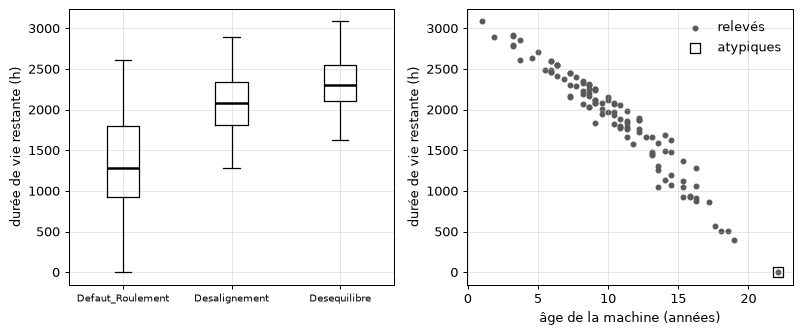

In [5]:
appr = df.loc[X_train.index]
print(appr.groupby("ETAT_LIGNE")[cible].describe()[["count", "min", "50%", "max"]].round(0).to_string())
print()
print(appr.groupby("mode_defaut_predominant")[cible].median().round(0).to_string())

fig, axes = plt.subplots(1, 2, figsize=(9, 3.8))
modes = sorted(appr["mode_defaut_predominant"].dropna().unique())
axes[0].boxplot([appr.loc[appr["mode_defaut_predominant"] == m, cible] for m in modes], tick_labels=modes,
                 medianprops={"color": "black", "linewidth": 2})
axes[0].set_ylabel("durée de vie restante (h)")
axes[0].tick_params(axis="x", labelsize=8)
axes[0].grid(alpha=0.3)
axes[1].scatter(appr["age_machine_annees"], appr[cible], s=14, color="0.35", label="relevés")
point = hors_bornes.loc[appr.index, cible] | hors_bornes.loc[appr.index, "age_machine_annees"]
axes[1].scatter(appr.loc[point, "age_machine_annees"], appr.loc[point, cible], s=60, marker="s",
                facecolor="none", edgecolor="black", label="atypiques")
axes[1].set_xlabel("âge de la machine (années)")
axes[1].set_ylabel("durée de vie restante (h)")
axes[1].legend(frameon=False)
axes[1].grid(alpha=0.3)
fig.tight_layout()
plt.show()

colonnes_ecartees = ["alarme_criticite", "ETAT_LIGNE"]
X_train = X_train.drop(columns=colonnes_ecartees)
X_test = X_test.drop(columns=colonnes_ecartees)

Lecture du résultat : sur les 112 machines d'apprentissage, l'état de la ligne suit la durée de vie restante : médiane de 2302 heures à l'état `OK`, de 1663 en `Degrade` et de 894 en `Maintenance`. L'état `Arret` ne se constate qu'une fois la durée de vie épuisée : 1 machine à l'arrêt, à 0 heure. Cet état, comme l'alarme de criticité, est une conséquence de la cible, pas une cause : on ne s'en sert pas pour prédire, et les deux colonnes sont retirées des entrées. Le mode de défaut compte aussi : les machines à défaut de roulement ont les durées de vie restantes les plus courtes, avec une médiane de 1281 heures, contre 2085 et 2302 heures pour les deux autres modes, ce que le diagramme en boîtes de gauche montre. À droite, le point entouré est la machine à l'arrêt : atypique par son âge comme par sa durée de vie restante.

### Étape 6 : construire le modèle de départ

Le modèle de départ est volontairement simple : une régression linéaire avec la seule variable âge de la machine. Elle contient quelques cases vides, que le pipeline remplit par la médiane de l'apprentissage. Il apprend sur `X_train` seul. Les autres colonnes sont laissées de côté : elles sont votre marge de progression.

In [6]:
variable = "age_machine_annees"

# Solution :
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline

modele = make_pipeline(SimpleImputer(strategy="median"), LinearRegression())
modele.fit(X_train[[variable]], y_train)
# Fin de la solution

Pipeline(steps=[('simpleimputer', SimpleImputer(strategy='median')),
                ('linearregression', LinearRegression())])

### Étape 7 : mesurer sur la base de test

Le modèle prédit les relevés qu'il n'a jamais vus. Trois indicateurs sont lus : le coefficient de détermination R², et deux erreurs en heures, la racine de l'erreur quadratique moyenne (RMSE) et l'erreur absolue moyenne (MAE).

In [7]:
from sklearn.metrics import mean_absolute_error, r2_score, root_mean_squared_error

y_pred = modele.predict(X_test[[variable]])
score_depart = r2_score(y_test, y_pred)
print(f"R² : {score_depart:.3f}")
print(f"RMSE : {root_mean_squared_error(y_test, y_pred):.0f} h")
print(f"MAE : {mean_absolute_error(y_test, y_pred):.0f} h")
print(f"durée de vie restante moyenne de la base de test : {y_test.mean():.0f} h")
print(f"pente : {modele[-1].coef_[0]:.0f} h par année d'âge")

R² : 0.883
RMSE : 208 h
MAE : 142 h
durée de vie restante moyenne de la base de test : 1851 h
pente : -148 h par année d'âge


Lecture du résultat : avec le seul âge, le R² est d'environ 0,88. L'erreur absolue moyenne est d'environ 142 heures pour une durée de vie moyenne de 1851 heures. La pente, d'environ -148 heures par année, décrit ces données dans ce domaine : elle ne prouve pas que vieillir une machine raccourcisse sa vie, l'âge est lié à l'usure et à d'autres grandeurs. C'est ce chiffre, mesuré sur des relevés que le modèle n'a jamais vus, que l'on a le droit d'annoncer.

## Pour aller plus loin : un modèle complet, choisi sans le test

Le modèle de départ de l'étape 6 reste le score de référence du défi. Les deux cellules suivantes montrent une démarche complète : tout ce qui a été décidé à l'exploration (cases vides remplies dans le pipeline, colonnes de conséquence écartées) est conservé. Les candidats sont comparés par validation croisée répétée sur l'apprentissage seul. Le meilleur est mesuré une seule fois sur le test, puis interrogé : quelles variables pèsent vraiment sur sa prédiction ? Les valeurs sont lues dans les sorties imprimées.

In [8]:
# Solution :
from sklearn.compose import make_column_transformer
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import RidgeCV
from sklearn.model_selection import RepeatedKFold, cross_val_score
from sklearn.preprocessing import OneHotEncoder, StandardScaler

numeriques_x = X_train.select_dtypes("number").columns.tolist()
categories = X_train.select_dtypes(exclude="number").columns.tolist()
preparation = make_column_transformer(
    (OneHotEncoder(handle_unknown="ignore"), categories),
    (make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), numeriques_x))
candidats = {
    "régression régularisée (ridge)": RidgeCV(alphas=[0.01, 0.1, 1, 10, 100]),
    "forêt aléatoire": RandomForestRegressor(n_estimators=300, random_state=GRAINE),
    "boosting du gradient": GradientBoostingRegressor(random_state=GRAINE)}
plis = RepeatedKFold(n_splits=5, n_repeats=3, random_state=GRAINE)
notes_cv = {}
for nom, estimateur in candidats.items():
    notes = cross_val_score(make_pipeline(preparation, estimateur), X_train, y_train, cv=plis, scoring="r2")
    notes_cv[nom] = notes.mean()
    print(f"{nom} : R² {notes.mean():.3f} +/- {notes.std():.3f} sur 15 plis")
nom_retenu = max(notes_cv, key=notes_cv.get)
print("modèle retenu par la validation croisée :", nom_retenu)
# Fin de la solution

régression régularisée (ridge) : R² 0.987 +/- 0.008 sur 15 plis
forêt aléatoire : R² 0.980 +/- 0.013 sur 15 plis
boosting du gradient : R² 0.984 +/- 0.008 sur 15 plis
modèle retenu par la validation croisée : régression régularisée (ridge)


In [9]:
# Solution :
from sklearn.inspection import permutation_importance

retenu = make_pipeline(preparation, candidats[nom_retenu]).fit(X_train, y_train)
r2_complet = r2_score(y_test, retenu.predict(X_test))
print(f"{nom_retenu}, mesuré une fois sur le test : R² {r2_complet:.3f}")
print(f"gain sur le modèle de départ : {r2_complet - score_depart:+.3f}")

importance = permutation_importance(retenu, X_test, y_test, n_repeats=20, random_state=GRAINE)
ordre = importance.importances_mean.argsort()[::-1][:5]
print("variables dont le mélange dégrade le plus le R² du test :")
for k in ordre:
    print(f"  {X_test.columns[k]} : {importance.importances_mean[k]:.3f}")
print("lecture : les premières variables portent l'essentiel de la prédiction ; les suivantes pèsent peu.")
# Fin de la solution

régression régularisée (ridge), mesuré une fois sur le test : R² 0.993
gain sur le modèle de départ : +0.111
variables dont le mélange dégrade le plus le R² du test :
  indice_degradation : 0.372
  age_machine_annees : 0.127
  vitesse_rotation_rpm : 0.123
  vibration_bande_1X_mm_s : 0.027
  pression_lubrification_bar : 0.021
lecture : les premières variables portent l'essentiel de la prédiction ; les suivantes pèsent peu.


## Le score de référence

Le score publié est le R² du modèle de départ de l'étape 6 sur la base de test. L'empreinte identifie cette base de test : si la vôtre diffère, le découpage n'est pas le même et les scores ne se comparent pas.

In [10]:
import hashlib

score = r2_score(y_test, modele.predict(X_test[[variable]]))
positions = ",".join(str(i) for i in sorted(X_test.index))
print("EMPREINTE_TEST =", hashlib.sha256(positions.encode("ascii")).hexdigest())
print("SCORE_REFERENCE r2 = %.3f" % score)

EMPREINTE_TEST = 698dd81846207bb444bf2781bde22ce045a0112247435a668f23ce9d77e4d425
SCORE_REFERENCE r2 = 0.883


## Synthèse

1. Résumer avant de modéliser : dimensions, types, cases vides par colonne et par ligne, quantiles. Les échelles et les manques décident des traitements à prévoir.
2. La règle de Tukey signale les valeurs atypiques sans les juger : on les garde si elles sont plausibles, on les corrige si elles sont impossibles.
3. Une colonne qui se constate après l'événement, comme l'état d'arrêt ou l'alarme, est une conséquence de la cible : elle est écartée des entrées.
4. Les cases vides se remplissent dans le pipeline, avec les statistiques de l'apprentissage seul.
5. Les candidats se comparent par validation croisée sur l'apprentissage ; le test ne sert qu'une fois, au modèle retenu.